## Model Training

### PPG Preprocessing
Three steps: mean removal, 4th-order Butterworth band-pass (0.5-5 Hz), and normalization by maximum absolute value.

### Environment setup
Run this first. The same notebook runs in two places:

- **Colab (training):** installs neurokit2, downloads the dataset from UCI onto the runtime (~3.3 GB, a few minutes; skipped if already there this session), mounts Google Drive, trains on the GPU and saves the model to `MyDrive/bp_results/<MODEL_NAME>.pt`. The runtime's disk is wiped when it disconnects, so the model is written to Drive every time validation improves.
- **VS Code / local CPU (everything else):** uses the local `data/cuff_less_bp_estimation` folder and **skips training**. Download the model file (e.g. `resnet_bp.pt`) from `MyDrive/bp_results` into `notebooks/resnet_models/` and the training cell loads it instead. Set `TRAIN = True` below to train locally anyway (slow on CPU).

In [ ]:
import os
import sys
import glob
import subprocess

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# train on Colab's GPU; locally, load the model trained there
TRAIN = IN_COLAB

UCI_URL = 'https://archive.ics.uci.edu/static/public/340/cuff+less+blood+pressure+estimation.zip'

if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'neurokit2'], check=True)

    # download straight from UCI onto the runtime (faster than copying from Drive)
    DATA_DIR = '/content/data'
    if len(glob.glob(f'{DATA_DIR}/Part_*.mat')) < 4:
        os.makedirs(DATA_DIR, exist_ok=True)
        print('Downloading dataset from UCI (~3.3 GB)...')
        subprocess.run(['wget', '-q', '-O', '/content/bp.zip', UCI_URL], check=True)
        subprocess.run(['unzip', '-q', '-o', '-j', '/content/bp.zip', '*Part_*.mat',
                        '-x', '__MACOSX/*', '-d', DATA_DIR], check=True)
        os.remove('/content/bp.zip')

    try:
        from google.colab import drive
        drive.mount('/content/drive')
        SAVE_DIR = '/content/drive/MyDrive/bp_results'
    except Exception as e:
        print(f'WARNING: Google Drive not mounted ({e}).')
        print('Results will be saved on the runtime only and are lost when it disconnects.')
        SAVE_DIR = '/content/results'
else:
    # find the project root whether the kernel starts in notebooks/ or the root itself
    ROOT = None
    for base in ('.', '..'):
        if os.path.isdir(os.path.join(base, 'data', 'cuff_less_bp_estimation')):
            ROOT = os.path.abspath(base)
            break
    if ROOT is None:
        raise FileNotFoundError('Could not find data/cuff_less_bp_estimation - run from the project root or notebooks/')
    DATA_DIR = os.path.join(ROOT, 'data', 'cuff_less_bp_estimation')
    SAVE_DIR = os.path.join(ROOT, 'notebooks', 'resnet_models')

parts = sorted(os.path.basename(p) for p in glob.glob(os.path.join(DATA_DIR, 'Part_*.mat')))
if len(parts) < 4:
    raise FileNotFoundError(f'Expected Part_1.mat - Part_4.mat in {DATA_DIR}, found {parts}')

os.makedirs(SAVE_DIR, exist_ok=True)
print(f'Colab: {IN_COLAB}, train: {TRAIN}')
print(f'Data:  {DATA_DIR} -> {parts}')
print(f'Save:  {SAVE_DIR}')

### Experiment settings
Switches for the accuracy experiments. The defaults are the **v1 baseline** (the paper's setup), so leaving them alone reproduces the first run exactly.

- Change one group of switches per run and give each run its own `MODEL_NAME`, so earlier models in Drive are not overwritten.
- To evaluate a model locally, set the switches to the ones it was trained with. The cell checks this against the model file and stops early if they differ.
- `AUGMENT` and `CONV_DROPOUT` only change training, so they never need to match when loading a model.
- `ALIGN` and `STRICT_QC` also change the dataset (rerun from the dataset cell) and the test set, so set them to the values a model was trained with when evaluating it.
- Changing `INPUT_CHANNELS` changes the dataset, so rerun from the dataset cell. Adding `'ecg'` (v4) also drops recordings whose ECG has missing values, so its test set differs slightly from the PPG-only runs (v1-v3, v4a).

In [ ]:
# v1 baseline (paper):      USE_GAP=False, KERNEL=3, INPUT_CHANNELS=('ppg',), LOSS='mse',   WEIGHT_DECAY=0.0
# v2 less overfitting:      USE_GAP=True,  KERNEL=3, INPUT_CHANNELS=('ppg',), LOSS='huber', WEIGHT_DECAY=1e-4
# v3 + whole-beat kernels:  USE_GAP=True,  KERNEL=7, INPUT_CHANNELS=('ppg',), LOSS='huber', WEIGHT_DECAY=1e-4
# v4 + derivatives and ECG: USE_GAP=True,  KERNEL=7, INPUT_CHANNELS=('ppg', 'd1', 'd2', 'ecg'), LOSS='huber', WEIGHT_DECAY=1e-4
# v4a (optional, no ECG):   USE_GAP=True,  KERNEL=7, INPUT_CHANNELS=('ppg', 'd1', 'd2'), LOSS='huber', WEIGHT_DECAY=1e-4
# v5 less overfitting:      v4 + AUGMENT=True, CONV_DROPOUT=0.1
# v6 cleaner data:          v5 + ALIGN=True, STRICT_QC=True (benchmark preprocessing, Gonzalez et al. 2023)
# v7 stronger weight decay: v6 + WEIGHT_DECAY=1e-3

MODEL_NAME = 'resnet_bp_v6'      # checkpoint file: <SAVE_DIR>/<MODEL_NAME>.pt, e.g. 'resnet_bp_v2'
USE_GAP = True               # True: global average pooling before the dense head (~66k head weights instead of 5.1M)
KERNEL = 7                  # conv kernel size: 3 sees ~0.3 s, 7 sees about one heartbeat
INPUT_CHANNELS = ('ppg', 'd1', 'd2', 'ecg')     # any of 'ppg', 'd1' (1st derivative), 'd2' (2nd derivative), 'ecg'
LOSS = 'huber'                  # 'mse' or 'huber'
WEIGHT_DECAY = 1e-4            # > 0 switches Adam to AdamW with this weight decay
AUGMENT = True                # True: random time shift (up to 1 s, same for every channel) + small noise on training windows
CONV_DROPOUT = 0.1            # > 0: drop whole channels after each residual block during training, e.g. 0.1
ALIGN = True                  # shift the ABP onto the PPG (max cross-correlation, up to 1 s) before labelling
STRICT_QC = True              # stricter window filter: heart rate 35-140, steady beats, PPG skewness >= 0

CONFIG = {'use_gap': USE_GAP, 'kernel': KERNEL, 'input_channels': list(INPUT_CHANNELS),
          'loss': LOSS, 'weight_decay': WEIGHT_DECAY, 'augment': AUGMENT, 'conv_dropout': CONV_DROPOUT,
          'align': ALIGN, 'strict_qc': STRICT_QC}
# checkpoints saved before these switches existed carry no config: they are the v1 baseline
BASELINE_CONFIG = {'use_gap': False, 'kernel': 3, 'input_channels': ['ppg'],
                   'loss': 'mse', 'weight_decay': 0.0, 'augment': False, 'conv_dropout': 0.0, 'align': False, 'strict_qc': False}
ARCH_KEYS = ('use_gap', 'kernel', 'input_channels')   # what must match to load a model (dropout and augmentation hold no weights)

if not set(INPUT_CHANNELS) <= {'ppg', 'd1', 'd2', 'ecg'}:
    raise ValueError(f'unknown channel in {INPUT_CHANNELS}')
if LOSS not in ('mse', 'huber'):
    raise ValueError(f'unknown LOSS {LOSS!r}')

MODEL_PATH = os.path.join(SAVE_DIR, f'{MODEL_NAME}.pt')
print(f'Model:  {MODEL_PATH} ({"found" if os.path.exists(MODEL_PATH) else "not there yet"})')
print(f'Config: {CONFIG}')

# local evaluation: catch mismatched switches now, before the slow dataset build
if not TRAIN and os.path.exists(MODEL_PATH):
    import torch
    saved_cfg = torch.load(MODEL_PATH, map_location='cpu', weights_only=False).get('config', BASELINE_CONFIG)
    mismatch = {k: (saved_cfg[k], CONFIG[k]) for k in ARCH_KEYS if saved_cfg[k] != CONFIG[k]}
    if mismatch:
        raise ValueError(f'{MODEL_NAME}.pt was trained with different switches (saved, current): {mismatch}')
    # data switches don't block loading, but they change the test set, so the numbers wouldn't match the training run
    data_mismatch = {k: (saved_cfg.get(k, False), CONFIG[k]) for k in ('align', 'strict_qc')
                     if saved_cfg.get(k, False) != CONFIG[k]}
    if data_mismatch:
        print(f'WARNING: {MODEL_NAME}.pt was trained on differently cleaned data (saved, current): {data_mismatch}')

In [1]:
import numpy as np
import h5py
from scipy.signal import find_peaks, correlate, correlation_lags
from scipy.stats import skew
import neurokit2 as nk
from matplotlib import pyplot as plt

FS = 125            # sampling rate (Hz)
WINDOW_SIZE = 625   # 5 seconds at 125 Hz


**1) Mean removal** - (`nk.signal_detrend`, order 0) subtract the signal mean to remove the constant offset.

**2) Filtering** - Butterworth band-pass, order 4, 0.5-5 Hz. NeuroKit2's `signal_filter` applies it with zero phase, so pulse peaks are not shifted in time.

**3) Normalization** - divide by the maximum absolute value so the signal lies in [-1, 1].

In [2]:
def remove_mean(ppg):
    # order=0 detrend fits and subtracts a constant, i.e. the mean
    return nk.signal_detrend(np.asarray(ppg, dtype=float), order=0)


def bandpass_filter(ppg, fs=FS, low=0.5, high=5.0, order=4):
    return nk.signal_filter(ppg, sampling_rate=fs, lowcut=low, highcut=high,
                            method='butterworth', order=order)


def normalize(ppg):
    peak = np.max(np.abs(ppg))
    return ppg / peak if peak > 0 else ppg


def preprocess_ppg(ppg, fs=FS):
    """Mean removal -> Butterworth band-pass -> max-abs normalization."""
    return normalize(bandpass_filter(remove_mean(ppg), fs))


### Labels and window quality filter
SBP/DBP labels come from the ABP window (median of beat peaks/valleys, same rule as `data_exploration.ipynb`). A window is kept only if it has a valid label and a usable PPG.

With `STRICT_QC=True`, windows must also pass the checks from the PPG benchmark paper (González et al., Sci Data 2023): resting heart rate 35-140 bpm in both PPG and ABP, steady beat-to-beat intervals and peak/valley heights, and non-negative PPG skewness (a signal quality index). The thresholds sit around the 90th-95th percentile of these statistics on this dataset and remove roughly 15% more windows.

In [3]:
def get_bp_labels(abp_window, fs=FS, strict=False):
    """(SBP, DBP) from one ABP window, or None if the window is unusable."""
    min_gap = fs * 0.4
    peaks, _ = find_peaks(abp_window, distance=min_gap)
    valleys, _ = find_peaks(-abp_window, distance=min_gap)
    if len(peaks) == 0 or len(valleys) == 0:
        return None

    sys_vals = abp_window[peaks]
    sys_vals = sys_vals[(sys_vals >= 70) & (sys_vals <= 220)]
    dia_vals = abp_window[valleys]
    dia_vals = dia_vals[(dia_vals >= 30) & (dia_vals <= 140)]
    if len(sys_vals) == 0 or len(dia_vals) == 0:
        return None

    if strict and len(peaks) >= 2 and not 35 <= 60 * fs / np.median(np.diff(peaks)) <= 140:
        return None     # ABP heart rate outside 35-140 bpm

    sbp, dbp = np.median(sys_vals), np.median(dia_vals)
    if sbp <= dbp or sbp - dbp < 10:
        return None
    return sbp, dbp


def good_ppg_window(ppg_win, fs=FS, min_hr=48, max_hr=180):
    """Reject flat/non-finite windows and windows whose beat count is physiologically implausible."""
    if not np.isfinite(ppg_win).all() or np.std(ppg_win) < 1e-3:
        return False
    peaks, _ = find_peaks(ppg_win, distance=int(0.33 * fs), prominence=0.2)
    n_sec = len(ppg_win) / fs
    return min_hr * n_sec / 60 <= len(peaks) <= max_hr * n_sec / 60


def strict_ppg_window(ppg_win, fs=FS, min_hr=35, max_hr=140, max_ibi_cv=0.15, max_amp_sd=0.2):
    """Benchmark-style checks on a normalized PPG window: resting heart rate, steady beat intervals
    (coefficient of variation), steady peak and valley heights, and skewness >= 0."""
    peaks, _ = find_peaks(ppg_win, distance=int(0.33 * fs), prominence=0.2)
    valleys, _ = find_peaks(-ppg_win, distance=int(0.33 * fs), prominence=0.2)
    if len(peaks) < 3 or len(valleys) < 3:
        return False
    ibi = np.diff(peaks) / fs
    return (min_hr <= 60 / np.median(ibi) <= max_hr
            and ibi.std() / ibi.mean() <= max_ibi_cv
            and np.std(ppg_win[peaks]) <= max_amp_sd and np.std(ppg_win[valleys]) <= max_amp_sd
            and skew(ppg_win) >= 0)


def align_lag(ppg_filtered, abp, fs=FS, max_lag=FS):
    """Samples by which the PPG trails the ABP, from the max cross-correlation within +/- max_lag (1 s).
    The ABP is band-passed like the PPG so its baseline doesn't dominate the correlation."""
    abp_filtered = bandpass_filter(remove_mean(abp))
    corr = correlate(ppg_filtered, abp_filtered, method='fft')
    lags = correlation_lags(len(ppg_filtered), len(abp_filtered))
    keep = np.abs(lags) <= max_lag
    return int(lags[keep][np.argmax(corr[keep])])


### Build the dataset
Load all four parts, window each recording, filter, label. `recording_id` is unique across parts so the split can be done by recording.

Each window holds one row per entry in `INPUT_CHANNELS`, so `X` has shape (windows, channels, 625). The derivatives come from the filtered PPG; the ECG gets its own 0.5-40 Hz band-pass because its QRS spikes are much sharper than a pulse wave. Every channel is normalized per window. The quality filter always looks at the PPG.

With `ALIGN=True`, each recording's ABP is shifted onto its PPG first (the pulse reaches the finger about 0.3 s after the arterial line), so each window's labels describe the same beats the model sees. Only the ABP moves relative to the inputs: the PPG and ECG are cut together, so the ECG-to-PPG timing the model can learn from is kept.

In [ ]:
# several channels as float32 would need ~5 GB, so they are stored as float16;
# the training loop converts each batch back to float32
X_DTYPE = np.float32 if len(INPUT_CHANNELS) == 1 else np.float16
NEED_DERIV = 'd1' in INPUT_CHANNELS or 'd2' in INPUT_CHANNELS
NEED_ECG = 'ecg' in INPUT_CHANNELS

X, y, rec_ids = [], [], []
lags = []
rec_counter = 0
n_total = 0

for part in range(1, 5):
    with h5py.File(f'{DATA_DIR}/Part_{part}.mat', 'r') as f:
        data = f[f'Part_{part}']
        for i in range(data.shape[0]):
            record = np.array(f[data[i, 0]]).T          # (3, n): PPG, ABP, ECG
            ppg, abp, ecg = record[0], record[1], record[2]
            if not (np.isfinite(ppg).all() and np.isfinite(abp).all()
                    and (not NEED_ECG or np.isfinite(ecg).all())):
                rec_counter += 1
                continue

            # mean removal + band-pass on the full recording, then window
            filtered = bandpass_filter(remove_mean(ppg))
            signals = {'ppg': filtered}
            if NEED_DERIV:
                signals['d1'] = np.gradient(filtered)
                signals['d2'] = np.gradient(signals['d1'])
            if NEED_ECG:
                signals['ecg'] = bandpass_filter(remove_mean(ecg), low=0.5, high=40.0)

            if ALIGN:
                # PPG[n] matches ABP[n - lag]: drop the unmatched ends; the inputs are cut together
                lag = align_lag(filtered, abp)
                lags.append(lag)
                if lag > 0:
                    signals = {k: v[lag:] for k, v in signals.items()}
                    abp = abp[:-lag]
                elif lag < 0:
                    signals = {k: v[:lag] for k, v in signals.items()}
                    abp = abp[-lag:]
                filtered = signals['ppg']

            n_windows = len(filtered) // WINDOW_SIZE
            for j in range(n_windows):
                s, e = j * WINDOW_SIZE, (j + 1) * WINDOW_SIZE
                n_total += 1
                win = normalize(filtered[s:e])
                labels = get_bp_labels(abp[s:e], strict=STRICT_QC)
                if labels is None or not good_ppg_window(win) or (STRICT_QC and not strict_ppg_window(win)):
                    continue
                X.append(np.stack([normalize(signals[c][s:e]) for c in INPUT_CHANNELS]).astype(X_DTYPE))
                y.append(labels)
                rec_ids.append(rec_counter)
            rec_counter += 1
    print(f'Part_{part} done: {len(X):,} windows kept so far')

X = np.stack(X)                         # (N, channels, 625)
y = np.array(y, dtype=np.float32)       # columns: SBP, DBP
rec_ids = np.array(rec_ids)
print(f'Kept {len(X):,} / {n_total:,} windows ({len(X)/n_total*100:.1f}%) from {len(np.unique(rec_ids)):,} recordings')
print(X.shape, X.dtype, y.shape)
if ALIGN:
    print(f'PPG trails ABP by a median {np.median(lags) / FS:.2f} s ({np.mean(np.array(lags) < 0):.1%} of recordings negative)')

### Split by recording
Windows from the same recording are near-duplicates, so whole recordings go to one split (70/15/15) to avoid leakage.

The splits are kept as index arrays (`train_idx`, `val_idx`, `test_idx`) into `X` rather than copies, because a multi-channel `X` can take several GB.

In [ ]:
rng = np.random.default_rng(42)
unique_recs = rng.permutation(np.unique(rec_ids))
n_train = int(0.70 * len(unique_recs))
n_val = int(0.15 * len(unique_recs))
train_recs = unique_recs[:n_train]
val_recs = unique_recs[n_train:n_train + n_val]
test_recs = unique_recs[n_train + n_val:]

train_idx = np.flatnonzero(np.isin(rec_ids, train_recs))
val_idx = np.flatnonzero(np.isin(rec_ids, val_recs))
test_idx = np.flatnonzero(np.isin(rec_ids, test_recs))
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

# standardize targets using training statistics only
y_mean, y_std = y_train.mean(axis=0), y_train.std(axis=0)
y_s = (y - y_mean) / y_std

print(f'train {len(train_idx):,}, val {len(val_idx):,}, test {len(test_idx):,} windows of shape {X.shape[1:]}')
print(f'target mean (SBP, DBP): {y_mean}, std: {y_std}')

Quick visual check: the first 5 s of one recording before and after preprocessing.

In [ ]:
with h5py.File(f'{DATA_DIR}/Part_1.mat', 'r') as f:
    rec = np.array(f[f['Part_1'][0, 0]]).T
raw = rec[0][:WINDOW_SIZE]
processed = normalize(bandpass_filter(remove_mean(rec[0]))[:WINDOW_SIZE])   # same steps as the dataset loop
labels = get_bp_labels(rec[1][:WINDOW_SIZE])
t = np.arange(WINDOW_SIZE) / FS

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(t, raw); axes[0].set(ylabel='Raw PPG', title='Before preprocessing')
label_text = f'SBP {labels[0]:.0f}, DBP {labels[1]:.0f}' if labels else 'no valid label'
axes[1].plot(t, processed); axes[1].set(ylabel='Preprocessed', xlabel='Time (s)',
                                        title=f'After preprocessing ({label_text})')
plt.tight_layout()

## 1D ResNet (PyTorch)
Architecture follows the referenced paper (IEEE SPACE 2025, DOI 10.1109/SPACE65882.2025.11171111):

- Input: one 5 s PPG window, shape 1 x 625
- Three residual blocks with 32, 64 and 128 filters. Each block: two Conv1d (kernel 3, zero padding) + BatchNorm + ReLU, a skip connection, then max-pooling (/2)
- Flatten -> Dense 512 -> Dropout 0.5
- Output head

The paper classifies into 4 AHA categories with a softmax head. Here the head is **2 linear outputs (standardized SBP, DBP)** so the model does regression, and the AHA category is derived from the predicted values afterwards.

Note: the paper's 99% accuracy comes from a random 80/20 split of windows, so windows from the same patient end up in both train and test. This notebook splits by recording, so expect noticeably weaker numbers. They are a more honest estimate of performance on unseen people.

**Switches** (see Experiment settings): `KERNEL` sets the conv kernel size, `INPUT_CHANNELS` sets the number of input channels, and `USE_GAP=True` replaces `Flatten` with global average pooling, so the dense head gets 128 numbers instead of 9,984.

In [ ]:
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, Subset, DataLoader

torch.manual_seed(42)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

BATCH_SIZE = 64     # paper: 64
EPOCHS = 70         # paper: 70 (early stopping below usually ends sooner)
LR = 1e-3
PATIENCE = 8        # epochs without real val MAE improvement before stopping
MIN_DELTA = 0.05    # mmHg: smaller gains still update the saved model but don't reset the patience counter

# one dataset over all windows; the splits are index subsets of it, so X is never copied
full_ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y_s))
train_ds = Subset(full_ds, train_idx.tolist())
val_ds = Subset(full_ds, val_idx.tolist())
test_ds = Subset(full_ds, test_idx.tolist())

# num_workers=0: worker processes are unreliable inside Jupyter on Windows
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=1024)
test_loader = DataLoader(test_ds, batch_size=1024)
# fixed sample of training windows, scored exactly like validation each epoch, so the train/val gap is measured in mmHg
train_eval_idx = np.sort(np.random.default_rng(0).choice(train_idx, size=min(20000, len(train_idx)), replace=False))
train_eval_loader = DataLoader(Subset(full_ds, train_eval_idx.tolist()), batch_size=1024)
print(f'device: {DEVICE}, {len(train_loader):,} train batches per epoch')

In [ ]:
class ResidualBlock(nn.Module):
    """Two conv-BN-ReLU layers with a skip connection, then max-pool /2."""

    def __init__(self, in_ch, out_ch, kernel_size=3, dropout=0.0):
        super().__init__()
        pad = kernel_size // 2
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size, padding=pad, bias=False)
        self.bn1 = nn.BatchNorm1d(out_ch)
        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size, padding=pad, bias=False)
        self.bn2 = nn.BatchNorm1d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        # 1x1 conv projects the input when the channel count changes
        self.skip = (nn.Identity() if in_ch == out_ch else
                     nn.Sequential(nn.Conv1d(in_ch, out_ch, 1, bias=False), nn.BatchNorm1d(out_ch)))
        self.pool = nn.MaxPool1d(2)
        # zeroes whole channels at random during training; nothing in eval mode
        self.drop = nn.Dropout1d(dropout) if dropout > 0 else nn.Identity()

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = self.relu(out + self.skip(x))
        return self.drop(self.pool(out))


class PPGResNet(nn.Module):
    def __init__(self, input_len=WINDOW_SIZE, in_channels=1, filters=(32, 64, 128), kernel_size=3,
                 use_gap=False, conv_dropout=0.0, n_outputs=2):
        super().__init__()
        blocks, in_ch = [], in_channels
        for f in filters:
            blocks.append(ResidualBlock(in_ch, f, kernel_size, conv_dropout))
            in_ch = f
        self.features = nn.Sequential(*blocks)
        if use_gap:
            # average each channel over time: (B, 128, 78) -> (B, 128)
            flatten = [nn.AdaptiveAvgPool1d(1), nn.Flatten()]
            n_flat = in_ch
        else:
            flatten = [nn.Flatten()]
            n_flat = in_ch * (input_len // 2 ** len(filters))     # 625 -> 312 -> 156 -> 78
        self.head = nn.Sequential(
            *flatten,
            nn.Linear(n_flat, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(512, n_outputs),
        )

    def forward(self, x):
        return self.head(self.features(x))


def build_model(cfg):
    return PPGResNet(in_channels=len(cfg['input_channels']), kernel_size=cfg['kernel'],
                     use_gap=cfg['use_gap'], conv_dropout=cfg.get('conv_dropout', 0.0))


model = build_model(CONFIG).to(DEVICE)
print(model)
print(f'{sum(p.numel() for p in model.parameters()):,} parameters')

### Training
Adam optimizer (as in the paper). The loss is computed on the standardized targets: MSE by default, replacing the paper's cross-entropy because this is regression, or Huber with `LOSS='huber'`, which punishes large misses less. `WEIGHT_DECAY > 0` switches to AdamW. The learning rate is halved when validation MAE plateaus, and the weights with the best validation MAE are kept. Training stops after `PATIENCE` epochs without a gain of at least `MIN_DELTA` mmHg in mean validation MAE; smaller gains still update the saved model but don't extend training.

The printed `val` loss is always MSE, so runs with different `LOSS` settings stay comparable. `MAE SBP/DBP train` is measured on a fixed sample of 20,000 training windows exactly like validation (eval mode, no augmentation), so the train/val MAE gap shows overfitting directly in mmHg.

With `AUGMENT=True`, each training batch gets a random time shift of up to 1 s (the same for every channel, so ECG-PPG timing is kept) and noise with SD 0.02. Validation and test windows are never augmented.

When `TRAIN` is False (local CPU), this cell loads the model saved by the Colab run instead of training, and the cells below evaluate that model.

In [ ]:
def predict(model, loader):
    """Predictions and targets in mmHg, shape (N, 2)."""
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for xb, yb in loader:
            preds.append(model(xb.to(DEVICE).float()).cpu().numpy())
            targets.append(yb.numpy())
    return (np.concatenate(preds) * y_std + y_mean,
            np.concatenate(targets) * y_std + y_mean)


AUG_SHIFT = FS        # largest time shift: 1 s
AUG_NOISE = 0.02      # noise SD on the [-1, 1] normalized scale


def augment(xb):
    """Random changes to a training batch: a circular time shift (the same for every channel,
    so ECG-PPG timing is kept) plus small Gaussian noise. Labels are unchanged."""
    n, c, length = xb.shape
    shifts = torch.randint(-AUG_SHIFT, AUG_SHIFT + 1, (n, 1), device=xb.device)
    idx = (torch.arange(length, device=xb.device) - shifts) % length        # (n, length)
    xb = torch.gather(xb, 2, idx[:, None, :].expand(n, c, length))
    return xb + AUG_NOISE * torch.randn_like(xb)


def save_checkpoint(state):
    # y_mean / y_std turn the model's standardized outputs back into mmHg; config rebuilds the architecture
    torch.save({'model': state, 'y_mean': y_mean, 'y_std': y_std, 'history': history,
                'config': CONFIG}, MODEL_PATH)


if TRAIN:
    criterion = nn.HuberLoss(delta=1.0) if LOSS == 'huber' else nn.MSELoss()
    if WEIGHT_DECAY > 0:
        optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

    history = {'train_loss': [], 'val_loss': [], 'val_mae_sbp': [], 'val_mae_dbp': [],
               'train_mae_sbp': [], 'train_mae_dbp': []}
    best_mae, best_state, bad_epochs = np.inf, None, 0
    patience_ref = np.inf     # val MAE at the last improvement of at least MIN_DELTA

    for epoch in range(1, EPOCHS + 1):
        t0 = time.time()
        model.train()
        running = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE).float(), yb.to(DEVICE)
            if AUGMENT:
                xb = augment(xb)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(train_ds)

        val_pred, val_true = predict(model, val_loader)
        val_loss = np.mean(((val_pred - val_true) / y_std) ** 2)     # always MSE, comparable across LOSS settings
        val_mae = np.abs(val_pred - val_true).mean(axis=0)
        scheduler.step(val_mae.mean())
        tr_pred, tr_true = predict(model, train_eval_loader)      # eval mode: no dropout, no augmentation
        train_mae = np.abs(tr_pred - tr_true).mean(axis=0)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_mae_sbp'].append(val_mae[0])
        history['val_mae_dbp'].append(val_mae[1])
        history['train_mae_sbp'].append(train_mae[0])
        history['train_mae_dbp'].append(train_mae[1])
        print(f'epoch {epoch:2d} | train {train_loss:.4f} | val {val_loss:.4f} | '
              f'MAE SBP/DBP train {train_mae[0]:.2f}/{train_mae[1]:.2f}, val {val_mae[0]:.2f}/{val_mae[1]:.2f} mmHg | '
              f'lr {optimizer.param_groups[0]["lr"]:.1e} | {time.time() - t0:.0f}s')

        if val_mae.mean() < best_mae:
            best_mae = val_mae.mean()
            # CPU copy so the checkpoint loads on machines without a GPU
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            # save every improvement so a Colab disconnect doesn't lose the run
            save_checkpoint(best_state)
        # only a gain of at least MIN_DELTA resets patience, so tiny gains don't keep training going
        if val_mae.mean() < patience_ref - MIN_DELTA:
            patience_ref, bad_epochs = val_mae.mean(), 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print(f'early stopping, best mean val MAE {best_mae:.2f} mmHg')
                break

    model.load_state_dict(best_state)
    save_checkpoint(best_state)
    print(f'saved best model to {MODEL_PATH}')
else:
    if not os.path.exists(MODEL_PATH):
        raise FileNotFoundError(f'{MODEL_PATH} not found. Train on Colab first, then download '
                                f'{MODEL_NAME}.pt from MyDrive/bp_results into {SAVE_DIR}')
    checkpoint = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint['model'])
    history = checkpoint.get('history')
    print(f'loaded trained model from {MODEL_PATH}')

In [ ]:
if history is None:
    print('no training history saved in this checkpoint')
else:
    epochs = np.arange(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history['train_loss'], label='train')
    axes[0].plot(epochs, history['val_loss'], label='validation')
    axes[0].set(xlabel='Epoch', ylabel='MSE (standardized)', title='Loss')
    axes[0].legend()
    axes[1].plot(epochs, history['val_mae_sbp'], label='SBP')
    axes[1].plot(epochs, history['val_mae_dbp'], label='DBP')
    if 'train_mae_sbp' in history:     # recorded from v5 on
        axes[1].plot(epochs, history['train_mae_sbp'], '--', color='C0', label='SBP train')
        axes[1].plot(epochs, history['train_mae_dbp'], '--', color='C1', label='DBP train')
    axes[1].set(xlabel='Epoch', ylabel='MAE (mmHg)', title='MAE (solid: validation, dashed: train)')
    axes[1].legend()
    plt.tight_layout()

### Test set evaluation
MAE, RMSE and mean error ± SD for SBP and DBP, compared with a naive baseline that always predicts the training-set mean.

**MASE** (mean absolute scaled error) is the model's MAE divided by the baseline's MAE, the main metric in the PPG benchmark paper (González et al., Sci Data 2023). 100% means no better than guessing the average; lower is better. Because it is relative, it can be compared across datasets with different BP ranges.

In [ ]:
test_pred, test_true = predict(model, test_loader)
baseline_pred = np.broadcast_to(y_mean, test_true.shape)
baseline_mae = np.abs(baseline_pred - test_true).mean(axis=0)

def report(name, pred, true):
    err = pred - true
    for k, target in enumerate(['SBP', 'DBP']):
        mae = np.abs(err[:, k]).mean()
        print(f'{name:9s} {target}: MAE {mae:5.2f} | MASE {mae / baseline_mae[k]:6.1%} | '
              f'RMSE {np.sqrt((err[:, k] ** 2).mean()):5.2f} | '
              f'ME {err[:, k].mean():+5.2f} ± {err[:, k].std():5.2f} mmHg')

report('Baseline', baseline_pred, test_true)
report('ResNet', test_pred, test_true)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for k, (ax, target) in enumerate(zip(axes, ['SBP', 'DBP'])):
    ax.scatter(test_true[:, k], test_pred[:, k], s=2, alpha=0.1)
    lims = [test_true[:, k].min(), test_true[:, k].max()]
    ax.plot(lims, lims, 'r--', lw=1)
    ax.set(xlabel=f'True {target} (mmHg)', ylabel=f'Predicted {target} (mmHg)', title=target)
plt.tight_layout()

### AHA category from predicted BP
Map true and predicted (SBP, DBP) to the four AHA classes used in the paper (Normal, Elevated, Hypertension stage 1, Hypertension stage 2) and score the result as a classification.

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

AHA_CLASSES = ['Normal', 'Elevated', 'HTN stage 1', 'HTN stage 2']

def aha_category(sbp, dbp):
    """0 Normal (<120 and <80), 1 Elevated (120-129 and <80),
    2 Stage 1 (130-139 or 80-89), 3 Stage 2 (>=140 or >=90)."""
    return np.select(
        [(sbp >= 140) | (dbp >= 90), (sbp >= 130) | (dbp >= 80), sbp >= 120],
        [3, 2, 1], default=0)

true_cls = aha_category(test_true[:, 0], test_true[:, 1])
pred_cls = aha_category(test_pred[:, 0], test_pred[:, 1])
print(classification_report(true_cls, pred_cls, labels=range(4), target_names=AHA_CLASSES, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(true_cls, pred_cls, labels=range(4), display_labels=AHA_CLASSES,
                                        normalize='true', values_format='.2f', cmap='Blues')
plt.title('AHA category (rows normalized)')
plt.tight_layout()

### Better readings without retraining
Two post-processing ideas, both applied to the trained model's predictions (no retraining, runs on CPU in about a minute). Everything is fitted on the **validation** set and then applied unchanged to the test set, so the test numbers stay honest.

- **30-second readings:** a real device would report BP averaged over a short period, not from a single 5 s window. Predictions and true labels are averaged over groups of `GROUP` consecutive kept windows of the same recording (6 = 30 s; slightly longer when rejected windows sit in between), then classified.
- **Stretched predictions:** the model squeezes its predictions towards the average. The stretch rescales them so their mean and spread match the true validation BP.
- **Tuned cutoffs:** the AHA cutoffs (SBP 120 / 130 / 140, DBP 80 / 90) are applied to *predicted* values. Shifting them, chosen to maximise validation macro-F1, compensates for the squeeze. The *true* classes always use the standard AHA cutoffs.

Report these as separate settings, not as the single-window result.

Setting (test set)                                         n  Accuracy  Macro-F1  MAE SBP  MAE DBP
5 s window, standard cutoffs                          79,154     0.499     0.469    12.76     6.51
5 s window, stretched                                 79,154     0.532     0.474    14.10     7.40
5 s window, tuned cutoffs [121, 130, 139, 94, 104]    79,154     0.512     0.473    12.76     6.51
30 s reading, standard cutoffs                        12,484     0.519     0.495    11.86     6.08
30 s reading, stretched                               12,484     0.562     0.507    13.00     6.83
30 s reading, tuned cutoffs [121, 130, 140, 89, 90]   12,484     0.527     0.498    11.86     6.08

30 s reading, tuned cutoffs:
              precision    recall  f1-score   support

      Normal      0.794     0.605     0.687      4516
    Elevated      0.259     0.489     0.338      1733
 HTN stage 1      0.304     0.468     0.368      2002
 HTN stage 2      0.769     0.489     0.598      4233

    a

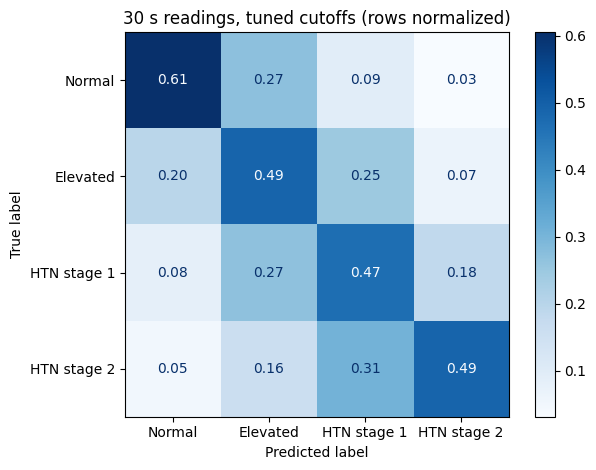

In [33]:
from sklearn.metrics import accuracy_score, f1_score

GROUP = 6   # windows per reading: 6 x 5 s = 30 s


def aha_category_cut(sbp, dbp, cuts):
    """AHA classes with adjustable cutoffs: cuts = (s1, s2, s3, d1, d2)."""
    s1, s2, s3, d1, d2 = cuts
    return np.select([(sbp >= s3) | (dbp >= d2), (sbp >= s2) | (dbp >= d1), sbp >= s1],
                     [3, 2, 1], default=0)


def group_average(pred, true, recs, n=GROUP):
    """Average predictions and labels over n consecutive kept windows of the same recording.
    Windows are in recording order, so each recording's windows are one contiguous run."""
    starts = np.flatnonzero(np.r_[True, recs[1:] != recs[:-1]])
    ends = np.r_[starts[1:], len(recs)]
    gp, gt = [], []
    for a, b in zip(starts, ends):
        for s in range(a, b - n + 1, n):      # full groups only
            gp.append(pred[s:s + n].mean(axis=0))
            gt.append(true[s:s + n].mean(axis=0))
    return np.array(gp), np.array(gt)


def fit_stretch(pred, true):
    """Linear rescaling so predictions match the mean and spread of the true values."""
    p_mean, p_std, t_mean, t_std = pred.mean(0), pred.std(0), true.mean(0), true.std(0)
    return lambda x: (x - p_mean) / p_std * t_std + t_mean


def tune_cutoffs(pred, true, rounds=3, span=15):
    """Coordinate search over the five cutoffs (+/- span mmHg) for the best macro-F1."""
    true_cls = aha_category(true[:, 0], true[:, 1])
    standard = [120, 130, 140, 80, 90]

    def score(c):
        return f1_score(true_cls, aha_category_cut(pred[:, 0], pred[:, 1], c),
                        labels=range(4), average='macro', zero_division=0)

    cuts, best = list(standard), score(standard)
    for _ in range(rounds):
        for i, base in enumerate(standard):
            for v in range(base - span, base + span + 1):
                c = list(cuts)
                c[i] = v
                if not (c[0] < c[1] < c[2] and c[3] < c[4]):
                    continue
                s = score(c)
                if s > best:
                    best, cuts = s, c
    return cuts


def evaluate(name, pred, true, cuts=(120, 130, 140, 80, 90)):
    true_cls = aha_category(true[:, 0], true[:, 1])
    pred_cls = aha_category_cut(pred[:, 0], pred[:, 1], cuts)
    mae = np.abs(pred - true).mean(axis=0)
    results.append((name, len(true), accuracy_score(true_cls, pred_cls),
                    f1_score(true_cls, pred_cls, labels=range(4), average='macro', zero_division=0),
                    mae[0], mae[1]))
    return pred_cls


val_pred, val_true = predict(model, val_loader)
val_recs, test_recs_w = rec_ids[val_idx], rec_ids[test_idx]

# 30 s readings
val_pred_g, val_true_g = group_average(val_pred, val_true, val_recs)
test_pred_g, test_true_g = group_average(test_pred, test_true, test_recs_w)

# fitted on validation only
stretch = fit_stretch(val_pred, val_true)
stretch_g = fit_stretch(val_pred_g, val_true_g)
cuts_1 = tune_cutoffs(val_pred, val_true)
cuts_g = tune_cutoffs(val_pred_g, val_true_g)

results = []
evaluate('5 s window, standard cutoffs', test_pred, test_true)
evaluate('5 s window, stretched', stretch(test_pred), test_true)
evaluate(f'5 s window, tuned cutoffs {cuts_1}', test_pred, test_true, cuts_1)
evaluate('30 s reading, standard cutoffs', test_pred_g, test_true_g)
evaluate('30 s reading, stretched', stretch_g(test_pred_g), test_true_g)
best_cls = evaluate(f'30 s reading, tuned cutoffs {cuts_g}', test_pred_g, test_true_g, cuts_g)

print(f'{"Setting (test set)":<52} {"n":>7} {"Accuracy":>9} {"Macro-F1":>9} {"MAE SBP":>8} {"MAE DBP":>8}')
for name, n, acc, f1, mae_s, mae_d in results:
    print(f'{name:<52} {n:>7,} {acc:>9.3f} {f1:>9.3f} {mae_s:>8.2f} {mae_d:>8.2f}')

print('\n30 s reading, tuned cutoffs:')
best_true = aha_category(test_true_g[:, 0], test_true_g[:, 1])
print(classification_report(best_true, best_cls, labels=range(4), target_names=AHA_CLASSES, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(best_true, best_cls, labels=range(4), display_labels=AHA_CLASSES,
                                        normalize='true', values_format='.2f', cmap='Blues')
plt.title('30 s readings, tuned cutoffs (rows normalized)')
plt.tight_layout()

### Load a saved model
Works on any machine, CPU included, as long as the `ResidualBlock` / `PPGResNet` cells above have been run. `build_model` rebuilds the architecture from the config stored in the file (older files without one are the v1 baseline). `MODEL_PATH` comes from the experiment settings cell; change it if your file is somewhere else.

In [ ]:
checkpoint = torch.load(MODEL_PATH, map_location='cpu', weights_only=False)
loaded = build_model(checkpoint.get('config', BASELINE_CONFIG))
loaded.load_state_dict(checkpoint['model'])
loaded.eval()
ckpt_mean, ckpt_std = checkpoint['y_mean'], checkpoint['y_std']

with torch.no_grad():
    out = loaded(torch.from_numpy(X[test_idx[:5]]).float()).numpy() * ckpt_std + ckpt_mean
for (sbp, dbp), (t_sbp, t_dbp) in zip(out, y_test[:5]):
    print(f'predicted {sbp:5.1f}/{dbp:4.1f}  true {t_sbp:5.1f}/{t_dbp:4.1f} mmHg')